# Q3. Which brain area (if any) has the highest density of ripples?

Hippocampal ripples are short (~20–150 ms) oscillations at about 110–250 Hz in mice. They ride on a **sharp wave**, a large slow deflection of the LFP,
and they coincide with a burst of spiking. They are measured on the channel where they are strongest (the pyramidal layer), and their density is reported as events per minute.

**Two problems with this dataset, and how they're handled:**
1. **The ripple band has mostly been filtered out.** The LFP is sampled at 500 Hz, so nothing above 250 Hz exists. The spectrum also shows that almost everything above ~130 Hz was removed (section 1).
   The dataset doesn't document this filter; it only says the LFP "has already undergone a preprocessing pipeline". The filtering is inferred from the spectrum.
   Detection therefore uses **110–180 Hz**, the part of the ripple band where some signal is left.
2. **Most high-frequency transients are artifacts shared by all three areas.** They happen at the same moment everywhere and are locked to the stimulus and the outcome, which points to movement or muscle activity (section 2).
   An event is kept only if it is **local**: at its peak, the other two areas show no high-frequency activity.

**Measure.** For each mouse and area: the rate of local events (per minute) on the area's best channel, meaning the channel with the most events, as in ripple studies.
Then section 4 checks whether these events look like ripples (a sharp wave and a spike burst).

**Statistics.** There is one value per mouse and area. The mean over the 18 mice gets a bootstrap 95% CI (resampling mice), and pairs of areas are compared with paired Wilcoxon tests.

The code lives in `c2p/q03_ripples.py`.

In [1]:
import sys; sys.path.insert(0, "..")
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.signal import sosfiltfilt

from c2p import AREAS, AREA_COLORS, DATA_DIR, FS_LFP, RESULTS_DIR, Recording
from c2p import q03_ripples as q3
from c2p.stats import ALL_PAIRS, area_bootstrap, per_mouse_tests

ev, ch, val = q3.compute()        # cached in results/; q3.compute(force=True) re-detects from the raw files (~20 min)
spectra = np.load(RESULTS_DIR / "q02_spectra.npz")
mice_ids = sorted(ch.mouse.unique())
print(f"{len(ev):,} candidate events, {ev.local.sum():,} local, on {len(ch)} channels of {len(mice_ids)} mice")

5,926,978 candidate events, 263,198 local, on 1862 channels of 18 mice


## 1. What is left of the ripple band

This is the spectrum above 60 Hz, using the spectra from Q2. Between 100 and 140 Hz the power drops 15–100× (depending on the area), while the trend at 20–80 Hz predicts only ~2×.
It then flattens into a **noise floor**. A steep cutoff followed by a flat floor is the signature of a low-pass filter. The table below the plot quantifies it.
On the right, the 150–240 Hz power of every channel is shown relative to the mouse's median channel. It is the same on every channel of every area, to within about 1%,
so any ripple signal there is buried. The usable range is roughly 110–150 Hz, at the low end of the ripple band.

,1/f slope (20–80 Hz),"drop 100→140 Hz, observed","drop 100→140 Hz, from trend",power at 200 Hz / trend
area 1,-1.475,15.032,1.642,0.024
area 2,-2.233,31.186,2.120,0.005
area 3,-2.078,97.256,2.012,0.003


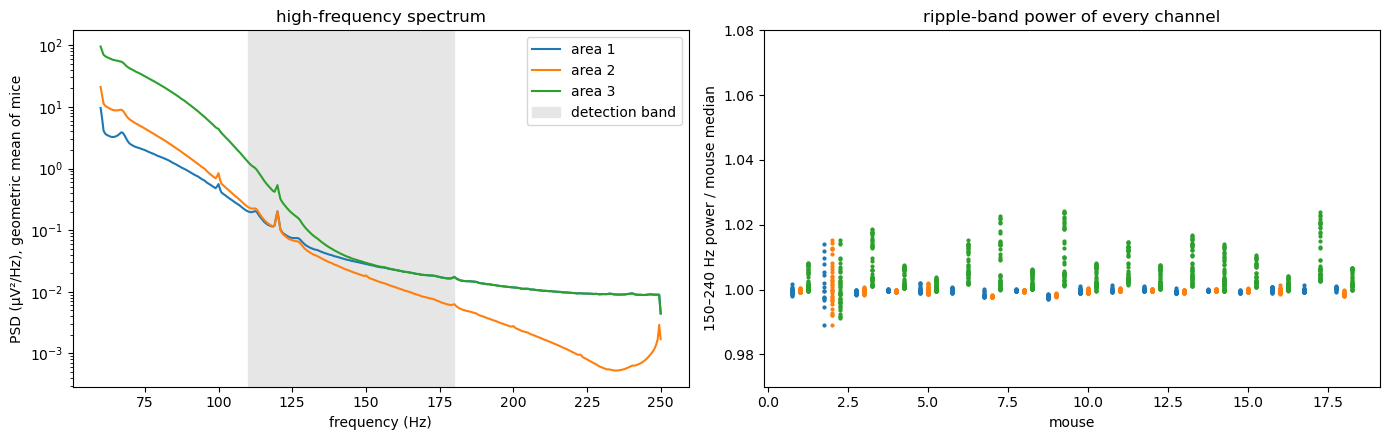

In [2]:
f = spectra["freqs"]
fig, (a1, a2) = plt.subplots(1, 2, figsize=(14, 4.5))
for a in AREAS:
    s = np.array([spectra[f"m{m}_a{a}"].mean(axis=0) for m in mice_ids])
    g = np.exp(np.log(s).mean(axis=0))
    sel = f >= 60
    a1.semilogy(f[sel], g[sel], color=AREA_COLORS[a], label=f"area {a}")
a1.axvspan(*q3.BAND, color="0.9", zorder=0, label="detection band")
a1.set(xlabel="frequency (Hz)", ylabel="PSD (µV²/Hz), geometric mean of mice", title="high-frequency spectrum")
a1.legend()

hf = (f >= 150) & (f <= 240)
for m in mice_ids:
    p = {a: spectra[f"m{m}_a{a}"][:, hf].sum(axis=1) for a in AREAS}
    ref = np.median(np.concatenate(list(p.values())))
    for a in AREAS:
        a2.scatter(np.full(len(p[a]), m) + (a - 2) * 0.25, p[a] / ref, s=4, color=AREA_COLORS[a])
a2.set(xlabel="mouse", ylabel="150–240 Hz power / mouse median", title="ripple-band power of every channel", ylim=(0.97, 1.08))
fig.tight_layout()

# How steep is the drop? Compare with the 1/f trend fitted at 20–80 Hz (mains peaks excluded)
at = lambda p, x: p[np.argmin(np.abs(f - x))]
rows = {}
for a in AREAS:
    g = np.exp(np.log(np.array([spectra[f"m{m}_a{a}"].mean(axis=0) for m in mice_ids])).mean(axis=0))
    sel = (f >= 20) & (f <= 80) & ~((f >= 49) & (f <= 69))
    k, b = np.polyfit(np.log(f[sel]), np.log(g[sel]), 1)
    trend = lambda x: np.exp(b) * x ** k
    rows[f"area {a}"] = {"1/f slope (20–80 Hz)": k, "drop 100→140 Hz, observed": at(g, 100) / at(g, 140),
                         "drop 100→140 Hz, from trend": trend(100) / trend(140),
                         "power at 200 Hz / trend": at(g, 200) / trend(200)}
pd.DataFrame(rows).T.round(3)

## 2. Shared transients are artifacts

A candidate event is any stretch of strong 110–180 Hz power, on any channel. Most candidates in every area coincide with high-frequency activity in **all** other areas.
The left panel shows the fraction of candidates that are local.
The right panel shows when the **shared** candidates happen relative to the task (best channel of area 1, all mice pooled). Their rate jumps right after the stimulus and around the outcome.
That pattern fits movement or muscle activity, not ripples, which wouldn't occur simultaneously in three separate structures.

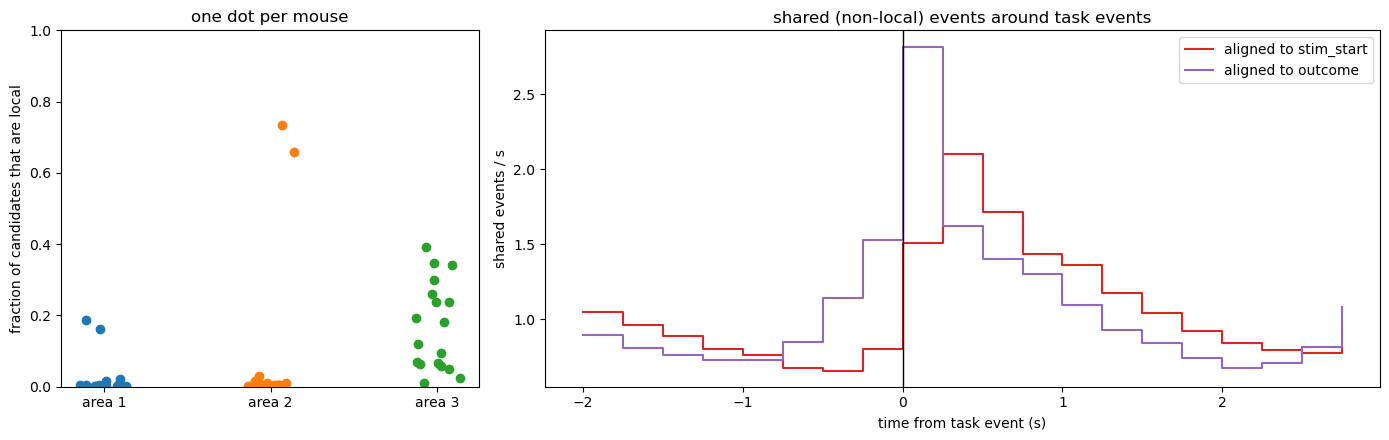

In [3]:
best = ch.loc[ch.groupby(["mouse", "area"]).rate_local_per_min.idxmax(), ["mouse", "area", "channel"]]
frac_local = ev.groupby(["mouse", "area"]).local.mean().unstack()

fig, (a1, a2) = plt.subplots(1, 2, figsize=(14, 4.5), gridspec_kw=dict(width_ratios=[1, 2]))
for a in AREAS:
    a1.scatter(np.full(len(frac_local), a) + np.random.default_rng(a).uniform(-0.15, 0.15, len(frac_local)),
               frac_local[a], color=AREA_COLORS[a])
a1.set(xticks=AREAS, xticklabels=[f"area {a}" for a in AREAS], ylabel="fraction of candidates that are local",
       title="one dot per mouse", ylim=(0, 1))

bins = np.arange(-2, 3.01, 0.25)
for event, color in [("stim_start", "tab:red"), ("outcome", "tab:purple")]:
    h, n_trials = np.zeros(len(bins) - 1), 0
    for m in mice_ids:
        trials = pd.read_csv(DATA_DIR / str(m) / "trial_data.csv", index_col=0, encoding="utf-8-sig")
        b = best[(best.mouse == m) & (best.area == 1)].channel.iloc[0]
        t = ev[(ev.mouse == m) & (ev.area == 1) & (ev.channel == b) & ~ev.local].t_s.to_numpy()
        h += np.histogram((t[:, None] - trials[event].to_numpy()[None, :]).ravel(), bins)[0]
        n_trials += len(trials)
    a2.step(bins[:-1], h / n_trials / 0.25, where="post", color=color, label=f"aligned to {event}")
a2.axvline(0, color="k", lw=1)
a2.set(xlabel="time from task event (s)", ylabel="shared events / s", title="shared (non-local) events around task events")
a2.legend()
fig.tight_layout()

## 3. Where along the probe the local events are

Each line is one mouse: the local event rate of every channel, from the deepest (0) to the most superficial.
In area 3, events are concentrated in specific layers, which is the signature of a laminar generator such as a hippocampal cell layer.
Some mice show two peaks. "Area 3" may span several hippocampal sub-regions (for example CA1 and dentate gyrus): the dataset gives no sub-region or layer information.
In areas 1 and 2 they are rare and flat across depth.

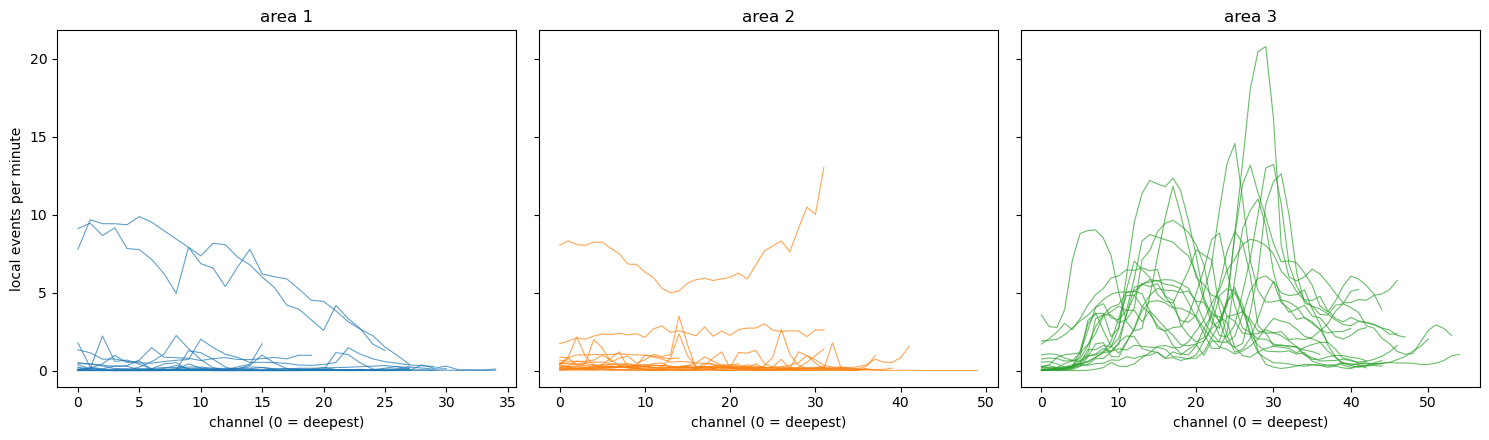

In [4]:
fig, axs = plt.subplots(1, 3, figsize=(15, 4.5), sharey=True)
for ax, a in zip(axs, AREAS):
    for m, g in ch[ch.area == a].groupby("mouse"):
        ax.plot(g.channel, g.rate_local_per_min, color=AREA_COLORS[a], lw=0.8, alpha=0.7)
    ax.set(xlabel="channel (0 = deepest)", title=f"area {a}")
axs[0].set_ylabel("local events per minute")
fig.tight_layout()

## 4. Do the local events look like ripples?

These averages are aligned to the peaks of the local events on the best channel of each area. The left panel is the wideband LFP: a **sharp wave** appears as a large slow deflection.
The right panel is the firing of the area's units relative to their mean rate: a ripple coincides with a **spike burst**.
Thin lines are individual mice, and the thick line is their average.

firing within ±25 ms of the events, relative to the mean rate (median over mice):


1    1.12
2    1.30
3    2.09
dtype: float64

most negative point of the event-triggered LFP, µV (mean over mice):


1    -37.0
2    -89.0
3   -561.0
dtype: float64

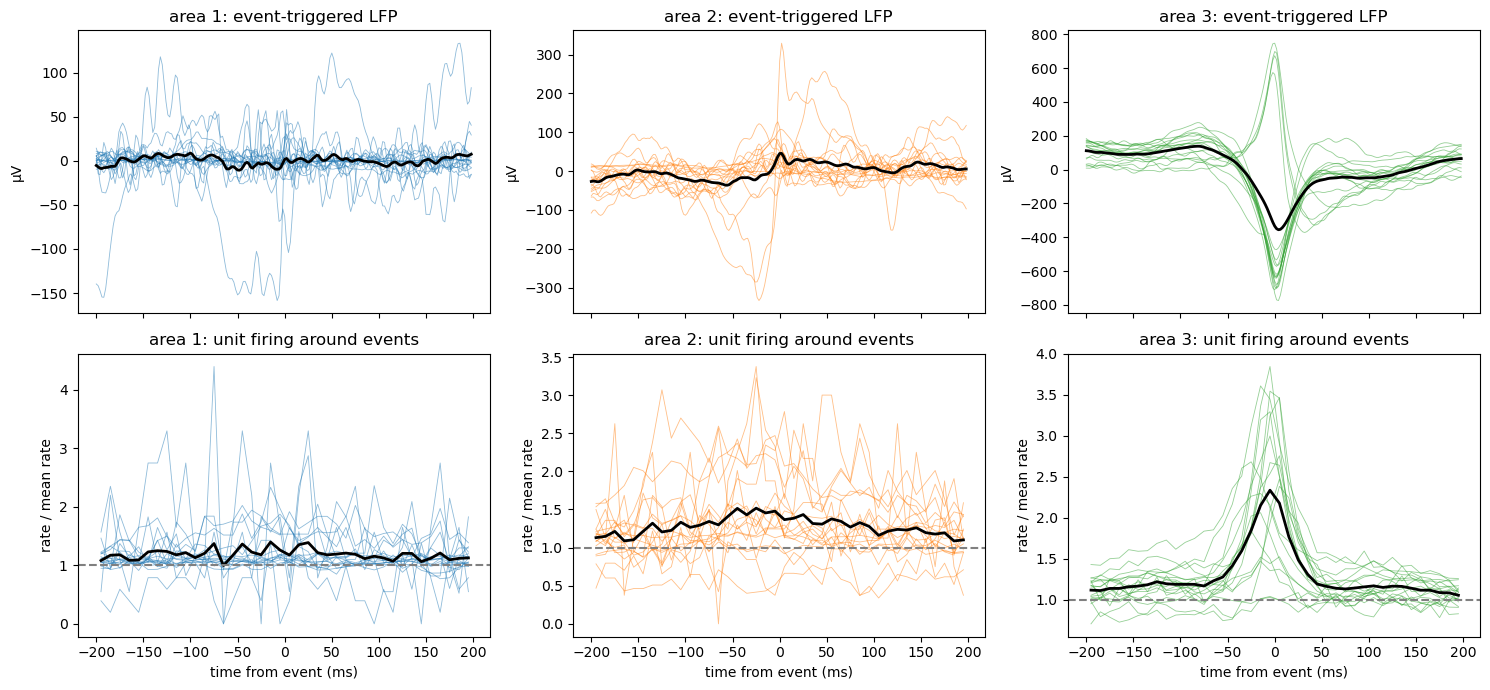

In [5]:
t_lfp = (np.arange(2 * int(q3.TRIG_HALF * FS_LFP)) - int(q3.TRIG_HALF * FS_LFP)) / FS_LFP * 1000
t_peth = (np.arange(-q3.TRIG_HALF, q3.TRIG_HALF, 0.01) + 0.005) * 1000
fig, axs = plt.subplots(2, 3, figsize=(15, 7), sharex=True)
peak_mod = {}
for k, a in enumerate(AREAS):
    lfps = np.array([val[f"m{m}_a{a}_lfp"] for m in mice_ids if f"m{m}_a{a}_lfp" in val])
    peths = np.array([val[f"m{m}_a{a}_peth"] for m in mice_ids if f"m{m}_a{a}_peth" in val])
    axs[0, k].plot(t_lfp, lfps.T, color=AREA_COLORS[a], lw=0.6, alpha=0.5)
    axs[0, k].plot(t_lfp, lfps.mean(axis=0), color="k", lw=2)
    axs[0, k].set(title=f"area {a}: event-triggered LFP", ylabel="µV")
    axs[1, k].plot(t_peth, peths.T, color=AREA_COLORS[a], lw=0.6, alpha=0.5)
    axs[1, k].plot(t_peth, peths.mean(axis=0), color="k", lw=2)
    axs[1, k].axhline(1, color="0.5", ls="--")
    axs[1, k].set(title=f"area {a}: unit firing around events", ylabel="rate / mean rate", xlabel="time from event (ms)")
    centre = (np.abs(t_peth) < 25)
    peak_mod[a] = pd.Series(peths[:, centre].mean(axis=1), index=[m for m in mice_ids if f"m{m}_a{a}_peth" in val])
fig.tight_layout()
mods = pd.DataFrame(peak_mod)
sw = pd.Series({a: np.mean([val[f"m{m}_a{a}_lfp"].min() for m in mice_ids]) for a in AREAS})
print("firing within ±25 ms of the events, relative to the mean rate (median over mice):"); display(mods.median().round(2))
print("most negative point of the event-triggered LFP, µV (mean over mice):"); display(sw.round(0))

### Examples

Here are four local events from the best area-3 channel of one mouse. Top: the wideband LFP on every second channel of area 3, deep at the bottom; the best channel is green.
Bottom: the 110–180 Hz trace on the best channel.

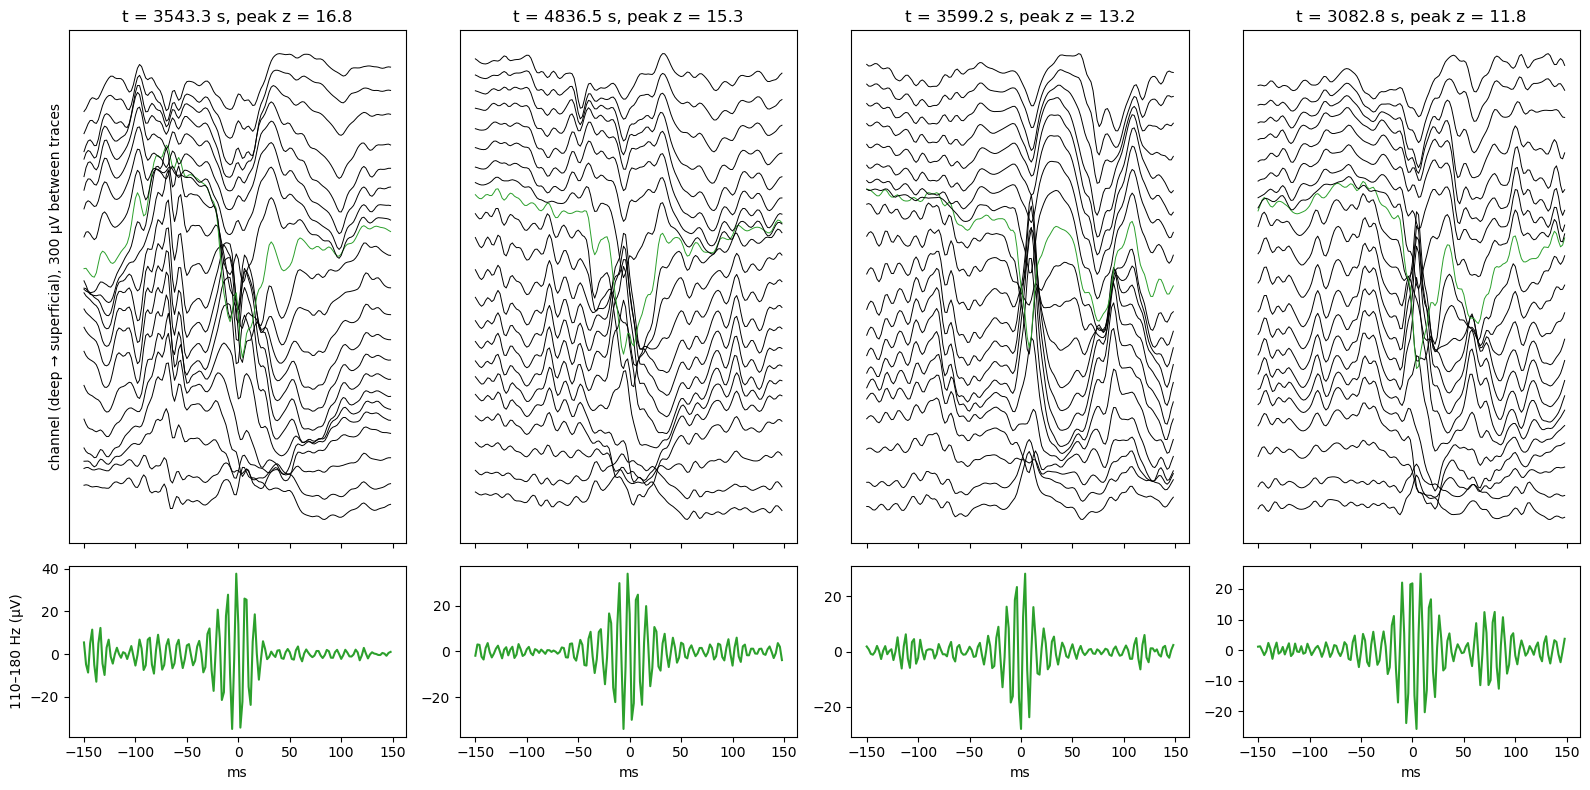

In [6]:
MOUSE = 9
rec = Recording.load(MOUSE)
b3 = best[(best.mouse == MOUSE) & (best.area == 3)].channel.iloc[0]
e = ev[(ev.mouse == MOUSE) & (ev.area == 3) & (ev.channel == b3) & ev.local].sort_values("peak_z", ascending=False)
examples = e.iloc[[0, 5, 10, 20]]
w = int(0.15 * FS_LFP)
fig, axs = plt.subplots(2, 4, figsize=(16, 8), gridspec_kw=dict(height_ratios=[3, 1]), sharex=True)
for k, (_, r) in enumerate(examples.iterrows()):
    i = int(r["sample"])
    x = np.asarray(rec.lfp[3][:, i - 3 * w:i + 3 * w], dtype=np.float64) * 1e6
    filt = sosfiltfilt(q3.SOS, x[b3])[2 * w:4 * w]
    x = x[:, 2 * w:4 * w]
    tt = (np.arange(2 * w) - w) / FS_LFP * 1000
    for c in range(b3 % 2, x.shape[0], 2):
        axs[0, k].plot(tt, x[c] - x[c].mean() + c * 150, color="k" if c != b3 else "tab:green", lw=0.7)
    axs[0, k].set(title=f"t = {r.t_s:.1f} s, peak z = {r.peak_z:.1f}", yticks=[])
    axs[1, k].plot(tt, filt, color="tab:green")
    axs[1, k].set(xlabel="ms")
axs[0, 0].set_ylabel("channel (deep → superficial), 300 µV between traces")
axs[1, 0].set_ylabel("110–180 Hz (µV)")
fig.tight_layout()

## 5. Density per mouse and area

The density is the local event rate on each area's best channel. Each line is one mouse, and the bars count how often each area had the highest density.

Friedman p = 5.6e-07


,mice where x > y,n mice,wilcoxon p,wilcoxon p (Bonferroni)
pair,,,,
area 1 vs area 2,5,18,4.7e-01,1.000000
area 1 vs area 3,0,18,7.6e-06,0.000023
area 2 vs area 3,0,18,7.6e-06,0.000023


mouse,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18
area,,,,,,,,,,,,,,,,,,
1,1.77,2.22,0.32,0.02,0.32,9.87,1.47,0.04,2.01,1.27,0.09,0.99,0.16,2.25,0.11,0.05,9.45,0.50
2,0.48,3.48,0.50,0.12,0.35,13.03,0.99,0.13,1.08,1.39,0.48,1.54,0.32,2.63,0.26,0.12,3.00,0.34
3,8.92,3.78,13.21,6.07,5.23,14.56,11.81,4.49,13.16,7.74,11.00,5.33,12.60,8.41,4.83,4.99,20.77,8.81


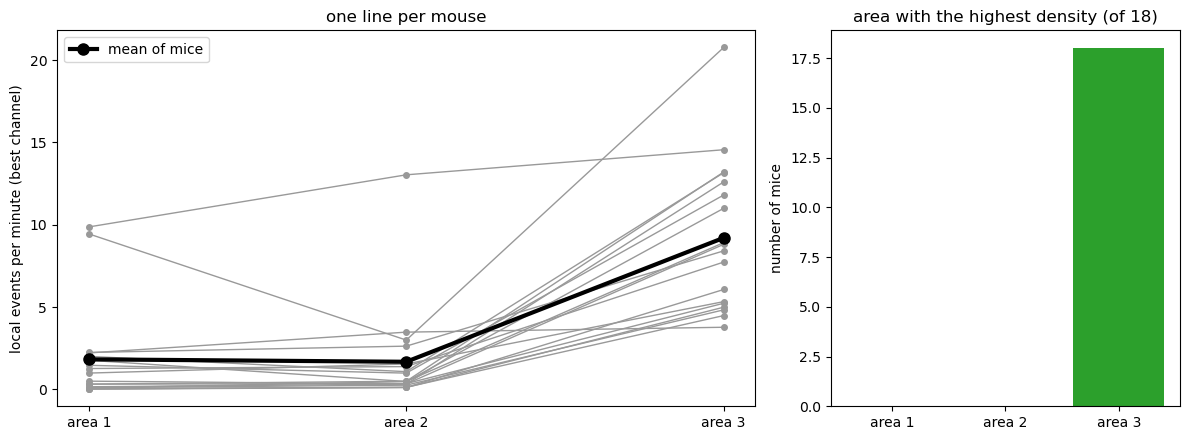

In [7]:
dens = ch.loc[ch.groupby(["mouse", "area"]).rate_local_per_min.idxmax(), ["mouse", "area", "channel", "rate_local_per_min"]]
dens = dens.rename(columns={"rate_local_per_min": "density"}).reset_index(drop=True)
per_mouse, friedman, wilc = per_mouse_tests(dens, "density")
highest = per_mouse.idxmax(axis=1).value_counts().reindex(AREAS, fill_value=0)

fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 4.5), gridspec_kw=dict(width_ratios=[2, 1]))
for m, row in per_mouse.iterrows():
    a1.plot(AREAS, row.values, "-o", color="0.6", ms=4, lw=1)
a1.plot(AREAS, per_mouse.mean().values, "-o", color="k", lw=3, ms=8, label="mean of mice")
a1.set(xticks=AREAS, xticklabels=[f"area {a}" for a in AREAS], ylabel="local events per minute (best channel)",
       title="one line per mouse")
a1.legend()
a2.bar([f"area {a}" for a in AREAS], highest.values, color=[AREA_COLORS[a] for a in AREAS])
a2.set(ylabel="number of mice", title=f"area with the highest density (of {len(per_mouse)})")
fig.tight_layout()
print("Friedman p =", f"{friedman.pvalue:.1e}")
display(wilc.style.format({"wilcoxon p": "{:.1e}"}))
per_mouse.round(2).T

## 6. Mean and 95% CI

There is one row per mouse and area, so the bootstrap just resamples mice (10,000 times).

In [8]:
t_dens, boot = area_bootstrap(dens, "density")
t_dens.round(3)

,estimate,ci_low,ci_high,p (diff = 0)
area 1,1.828,0.689,3.326,NaN
area 2,1.680,0.657,3.218,NaN
area 3,9.207,7.230,11.349,NaN
area 1 − area 2,0.147,-0.549,1.059,0.789
area 1 − area 3,-7.379,-8.894,-5.876,0.000
area 2 − area 3,-7.526,-9.581,-5.531,0.000


## 7. Robustness

The answer shouldn't depend on the arbitrary choices. Each row recomputes the per-mouse densities after one change:
- the median channel instead of the best channel (no channel selection at all);
- a stricter or looser locality criterion (other areas' index < 1.0 or < 2.0);
- stricter peak thresholds (z > 6 or z > 8; detection already requires z > 5);
- **no artifact rejection at all**, for comparison. This row counts the shared transients that section 2 showed are artifacts.

In [9]:
def densities(events, channels, how="best"):
    n = events.groupby(["mouse", "area", "channel"]).size()
    c = channels.set_index(["mouse", "area", "channel"])
    rate = (n.reindex(c.index, fill_value=0) / c.duration_min).rename("rate").reset_index()
    agg = rate.groupby(["mouse", "area"]).rate.max() if how == "best" else rate.groupby(["mouse", "area"]).rate.median()
    return agg.unstack()

variants = {
    "main: local, best channel": densities(ev[ev.local], ch),
    "median channel": densities(ev[ev.local], ch, how="median"),
    "locality: others < 1.0": densities(ev[ev.others_max < 1.0], ch),
    "locality: others < 2.0": densities(ev[ev.others_max < 2.0], ch),
    "peak z > 8": densities(ev[ev.local & (ev.peak_z > 8)], ch),
    "peak z > 6": densities(ev[ev.local & (ev.peak_z > 6)], ch),
    "NO artifact rejection": densities(ev, ch),
}
rows = {}
for name, pm in variants.items():
    rows[name] = {**{f"area {a}": pm[a].mean() for a in AREAS},
                  "highest (mean)": f"area {pm.mean().idxmax()}",
                  "highest in n mice": dict(pm.idxmax(axis=1).value_counts().sort_index())}
pd.DataFrame(rows).T

,area 1,area 2,area 3,highest (mean),highest in n mice
"main: local, best channel",1.82757,1.680085,9.206552,area 3,{3: 18}
median channel,0.843698,0.775601,2.631846,area 3,"{1: 1, 2: 1, 3: 16}"
locality: others < 1.0,0.72544,1.023203,7.09559,area 3,"{2: 1, 3: 17}"
locality: others < 2.0,4.001283,3.102854,10.929213,area 3,"{1: 1, 2: 2, 3: 15}"
peak z > 8,0.081596,0.198529,1.354744,area 3,"{2: 1, 3: 17}"
peak z > 6,0.582056,0.727889,4.612471,area 3,"{2: 1, 3: 17}"
NO artifact rejection,65.849109,56.825777,46.825882,area 1,"{1: 16, 2: 2}"


## 8. Answer for the questionnaire

In [10]:
answer = t_dens.iloc[:3, :3].copy()
answer.columns = ["Mean", "CI low", "CI high"]
answer["95% C.I."] = answer.apply(lambda r: f"[{r['CI low']:.2f}, {r['CI high']:.2f}]", axis=1)
answer["Units"] = "events/min"
answer = answer[["Mean", "95% C.I.", "Units"]].round(2)
answer.to_csv(RESULTS_DIR / "q03_answer.csv")
answer

,Mean,95% C.I.,Units
area 1,1.83,"[0.69, 3.33]",events/min
area 2,1.68,"[0.66, 3.22]",events/min
area 3,9.21,"[7.23, 11.35]",events/min


### Write it into the questionnaire

In [11]:
from c2p.questionnaire import fill_pdf, record_answer

m = t_dens.estimate
p_vs = wilc["wilcoxon p"]
explanation = (
    f"The LFP is sampled at 500 Hz and its spectrum indicates low-pass filtering during preprocessing (not documented): "
    f"power drops 15-100x from 100 to 140 Hz, against ~2x expected from the 1/f trend, and above ~150 Hz only a flat "
    f"noise floor remains, identical on all channels. I therefore detected ripples in 110–180 Hz, the lowest part of the "
    f"ripple band, on every channel over the whole recording (Hilbert envelope, robust z-score, events above z = 2 "
    f"lasting 15–300 ms with a peak above z = 5). Most candidates occurred simultaneously in all three areas and were "
    f"locked to stimulus and outcome, so I treated them as movement/EMG artifacts and kept only local events, during "
    f"which the other two areas showed no high-frequency activity. Density is the rate of local events on each area's "
    f"best channel, giving one value per mouse and area, with a bootstrap CI over mice. Area 3 had the highest density "
    f"in all {len(per_mouse)} mice ({m['area 3']:.1f} vs {m['area 1']:.1f} and {m['area 2']:.1f} events/min; "
    f"Wilcoxon p < 0.001 against each other area). Only in area 3 did the events show the hallmarks of sharp-wave "
    f"ripples: a laminar depth profile, a large negative sharp wave ({sw[3]:.0f} µV on average) and a "
    f"{mods[3].median():.1f}-fold increase of local firing. The result holds with the median channel and with other "
    f"locality and amplitude thresholds. Because most of the ripple band was filtered out, absolute densities are "
    f"probably underestimated."
)
explanation += " Pairwise p-values are Bonferroni-corrected for the three comparisons."
print(len(explanation.split()), "words")
record_answer(3, choice=2,                                   # 0 = area 1, 1 = area 2, 2 = area 3, 3 = not enough data
              rows=[(f"{r.Mean:.2f}", r["95% C.I."], r.Units) for _, r in answer.iterrows()],
              explanation=explanation)
print(fill_pdf())
print(explanation)

241 words


/home/dariosannino/con2phys/docs/questionnaire_filled.pdf
The LFP is sampled at 500 Hz and its spectrum indicates low-pass filtering during preprocessing (not documented): power drops 15-100x from 100 to 140 Hz, against ~2x expected from the 1/f trend, and above ~150 Hz only a flat noise floor remains, identical on all channels. I therefore detected ripples in 110–180 Hz, the lowest part of the ripple band, on every channel over the whole recording (Hilbert envelope, robust z-score, events above z = 2 lasting 15–300 ms with a peak above z = 5). Most candidates occurred simultaneously in all three areas and were locked to stimulus and outcome, so I treated them as movement/EMG artifacts and kept only local events, during which the other two areas showed no high-frequency activity. Density is the rate of local events on each area's best channel, giving one value per mouse and area, with a bootstrap CI over mice. Area 3 had the highest density in all 18 mice (9.2 vs 1.8 and 1.7 events/min

## Conclusion

**Area 3 has the highest ripple density.** It is about 9 local events/min, against about 2 in areas 1 and 2, and it is the highest in all 18 mice. Only area 3's events look like sharp-wave ripples.

**Caveat.** The ripple band is mostly filtered out of this LFP, so the events are detected on the low edge of the band (110–180 Hz).
The comparison between areas is robust, but the absolute rates are not comparable with published ripple rates.
The ripples, together with the sharp wave that reverses sign across depth, suggest that area 3 is (or contains) **hippocampus**.
The dataset doesn't say which sub-regions; area 3 spans ~1 mm of probe and could cover CA1, CA3 or the dentate gyrus.
Theta (~7 Hz) is **not** evidence for this: all three areas have a similar theta peak, about 3.5× above their 1/f trend.